# Day 2 - Từ annotation YOLO đến detector YOLO26

Notebook này chạy **sau** khi nhãn 50 ảnh train đã qua cổng gold-set. Tập `eval` 10 ảnh không được dùng để train.

Quy trình chuẩn: bạn **fork repo đề bài**, gán nhãn, **commit và push** `dataset/labels/train/` lên repo của mình, rồi chỉ cần dán URL repo vào `REPO_URL` ở cell đầu tiên — Colab sẽ tự clone repo, train và đánh giá, không cần upload file.

Bài cá nhân. Hạn nộp: 11:59 trưa ngày hôm sau buổi lab (UTC+7); ca 09/11/2026 nộp trước 11:59 ngày 10/11/2026.

## Kiểm tra trước khi chạy

- Đã **fork repo đề bài**, gán nhãn và **commit + push** `dataset/labels/train/` lên repo của bạn.
- Ở cell tiếp theo, dán **URL repo của bạn** vào `REPO_URL` — notebook tự clone, không cần upload file.
- Không có `gold_train_labels/` trong repo.
- Chạy từ trên xuống dưới; giữ nguyên `data.yaml` và split eval.
- mAP đo model; F1/IoU ở script trước đó đo chất lượng nhãn con người.

In [2]:
%pip -q install -U ultralytics

from pathlib import Path
import json
import os
import shutil
import subprocess
import torch
import yaml
from ultralytics import YOLO

# ==================================================================
# Bước 1 (bắt buộc): dán URL repo fork của bạn vào REPO_URL
#
# Dòng chuẩn của bài:
#   1. Fork repo đề bài, đổi tên theo chuẩn nộp
#      (K5-L2-DAY02-HoVaTen-MSSV-ObjectDetection).
#   2. Gán nhãn 50 ảnh, commit và push dataset/labels/train/ lên repo của bạn.
#   3. Mở notebook này trong Colab, dán URL repo, chạy cell này:
#      notebook tự clone repo của bạn và train, không cần upload file.
#
# Ví dụ:
#   REPO_URL = 'https://github.com/your-username/K5-L2-DAY02-HoVanA-20241234-ObjectDetection'
# ==================================================================
REPO_URL = 'https://github.com/bayvai20kg/K5-L2-DAY02-VuGiaKhang-2A202604069-ObjectDetection'
assert 'your-username' not in REPO_URL, (
    'Hãy dán URL repo fork của bạn (đã commit + push nhãn) vào REPO_URL.'
)

# Trên Colab clone về /content/Day2-Lab; chạy ngoài Colab thì dùng ./Day2-Lab.
LAB_ROOT = Path('/content/Day2-Lab') if Path('/content').is_dir() else Path('Day2-Lab')

if LAB_ROOT.exists():
    # Chạy lại cell trong cùng phiên Colab: khôi phục các file đã được sửa
    # (ví dụ data.yaml ở lần chạy trước) rồi kéo bản mới nhất từ GitHub.
    # Nếu thư mục không phải bản clone của repo, xóa /content/Day2-Lab rồi chạy lại.
    print('Đã có sẵn thư mục, pull nội dung mới nhất từ GitHub...')
    subprocess.run(['git', '-C', str(LAB_ROOT), 'checkout', '--', '.'], check=True)
    subprocess.run(['git', '-C', str(LAB_ROOT), 'pull', '--ff-only'], check=True)
else:
    print(f'Clone {REPO_URL} -> {LAB_ROOT}')
    env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
    try:
        subprocess.run(['git', 'clone', REPO_URL, str(LAB_ROOT)], check=True, env=env)
    except subprocess.CalledProcessError:
        # Repo private: clone bằng token tài khoản GitHub của bạn trong Colab.
        # Nếu chưa: menu Tools -> sign in to GitHub, rồi chạy lại cell này.
        from google.colab import auth
        token = auth.user_token('github')
        auth_url = REPO_URL.replace('https://github.com', f'https://{token}@github.com')
        subprocess.run(['git', 'clone', auth_url, str(LAB_ROOT)], check=True)

last_commit = subprocess.run(
    ['git', '-C', str(LAB_ROOT), 'log', '-1', '--oneline'],
    check=True, capture_output=True, text=True,
).stdout.strip()
print('commit mới nhất trong repo:', last_commit)

DATA_YAML = LAB_ROOT / 'data.yaml'
TRAIN_IMAGES = LAB_ROOT / 'dataset/images/train'
TRAIN_LABELS = LAB_ROOT / 'dataset/labels/train'
EVAL_IMAGES = LAB_ROOT / 'dataset/images/eval'
EVAL_LABELS = LAB_ROOT / 'dataset/labels/eval'
RUNS = LAB_ROOT / 'outputs/yolo26_runs'
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# Ultralytics resolves a relative `path:` in data.yaml against its own global
# datasets dir, not against data.yaml's own folder. Rewrite it to an absolute
# path so training works regardless of where the repo was cloned.
_data_cfg = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))
_data_cfg['path'] = str((LAB_ROOT / 'dataset').resolve())
DATA_YAML.write_text(yaml.dump(_data_cfg, allow_unicode=True, sort_keys=False), encoding='utf-8')

print('LAB_ROOT:', LAB_ROOT.resolve())
print('device:', DEVICE)

Clone https://github.com/bayvai20kg/K5-L2-DAY02-VuGiaKhang-2A202604069-ObjectDetection -> /content/Day2-Lab
commit mới nhất trong repo: 5d5baa4 kết quả
LAB_ROOT: /content/Day2-Lab
device: 0


In [3]:
def image_stems(directory):
    return {p.stem for ext in ('*.jpg', '*.jpeg', '*.png') for p in directory.glob(ext)}

train_images = image_stems(TRAIN_IMAGES)
train_labels = {p.stem for p in TRAIN_LABELS.glob('*.txt')}
eval_images = image_stems(EVAL_IMAGES)
eval_labels = {p.stem for p in EVAL_LABELS.glob('*.txt')}
assert len(train_images) == 50, f' cần 50 train images, thấy {len(train_images)}'
assert train_images == train_labels, f'train images/labels lệch: {sorted(train_images ^ train_labels)[:5]}'
assert len(eval_images) == 10 and eval_images == eval_labels, 'eval phải đủ 10 ảnh và nhãn'
print(f'OK: {len(train_images)} train + {len(eval_images)} eval; eval không đi vào train.')

OK: 50 train + 10 eval; eval không đi vào train.


## Huấn luyện

Bài thực hành dùng checkpoint `yolo26n.pt`. Với 50 ảnh, dùng model nano và ít epoch để minh họa vòng lặp dữ liệu; thời gian/metric không dùng làm benchmark sản phẩm.

In [4]:
model = YOLO('yolo26n.pt')
train_result = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=-1,
    device=DEVICE,
    project=str(RUNS),
    name='vehicle_annotation',
    exist_ok=True,
    seed=20260909,
    plots=True,
)
BEST = Path(model.trainer.best)
print('best checkpoint:', BEST)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Day2-Lab/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle_annotation, nbs=64, nms=None, opset=None, optimize=Fa

## Đánh giá đúng tập eval

`data.yaml` trỏ `val` tới 10 ảnh eval đã có nhãn. Không đổi `val` sang train để làm đẹp mAP. Ghi lại mAP50, mAP50-95, precision và recall.

Tập `eval` cũng được dùng làm validation trong quá trình train và chọn `best.pt`, nên không phải test set độc lập.

In [5]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='val', device=DEVICE, plots=True, project=str(RUNS), name='vehicle_eval', exist_ok=True)
summary = {
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50),
    'map50_95': float(metrics.box.map),
    'eval_images': len(eval_images),
    'checkpoint': str(BEST),
}
metrics_path = LAB_ROOT / 'outputs/model_eval_metrics.json'
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1940.4±407.6 MB/s, size: 76.8 KB)
val: Scanning /content/Day2-Lab/dataset/labels/eval.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.1it/s 0.2s
                   all         10        113      0.529      0.549        0.5      0.354
                   car         10         94      0.883      0.745      0.841      0.599
                 truck          5          5      0.205        0.2      0.302      0.262
                   bus          2          2      0.332        0.5      0.165      0.116
                   van          6         12      0.698       0.75      0.693      0.438
Speed: 0.4ms preprocess, 3.9ms inference, 0

In [6]:
# Kiểm tra trực quan một vài ảnh eval; đây là bước bắt buộc trong báo cáo.
prediction_dir = LAB_ROOT / 'outputs/eval_predictions'
results = best_model.predict(source=str(EVAL_IMAGES), conf=0.25, device=DEVICE, save=True, project=str(prediction_dir), name='visuals', exist_ok=True)
PRED_SAVE_DIR = Path(results[0].save_dir)
print('predictions saved to:', PRED_SAVE_DIR)
archive = shutil.make_archive(str(LAB_ROOT / 'outputs/day2_colab_outputs'), 'zip', LAB_ROOT / 'outputs')
print('Đã tạo:', archive)


image 1/10 /content/Day2-Lab/dataset/images/eval/drive_051.jpg: 640x640 6 cars, 14.3ms
image 2/10 /content/Day2-Lab/dataset/images/eval/drive_052.jpg: 640x640 5 cars, 29.0ms
image 3/10 /content/Day2-Lab/dataset/images/eval/drive_053.jpg: 640x640 6 cars, 1 van, 17.4ms
image 4/10 /content/Day2-Lab/dataset/images/eval/drive_054.jpg: 640x640 5 cars, 21.5ms
image 5/10 /content/Day2-Lab/dataset/images/eval/drive_055.jpg: 640x640 3 cars, 20.6ms
image 6/10 /content/Day2-Lab/dataset/images/eval/drive_056.jpg: 640x640 11 cars, 32.6ms
image 7/10 /content/Day2-Lab/dataset/images/eval/drive_057.jpg: 640x640 5 cars, 1 bus, 52.6ms
image 8/10 /content/Day2-Lab/dataset/images/eval/drive_058.jpg: 640x640 19 cars, 5 vans, 49.2ms
image 9/10 /content/Day2-Lab/dataset/images/eval/drive_059.jpg: 640x640 6 cars, 1 truck, 28.8ms
image 10/10 /content/Day2-Lab/dataset/images/eval/drive_060.jpg: 640x640 7 cars, 1 van, 51.1ms
Speed: 1.6ms preprocess, 31.7ms inference, 3.5ms postprocess per image at shape (1, 3, 6

## Xem trực tiếp kết quả dự đoán

Hiển thị 10 ảnh eval kèm box dự đoán ngay trong notebook, không cần tải file `.zip` về mới xem được.

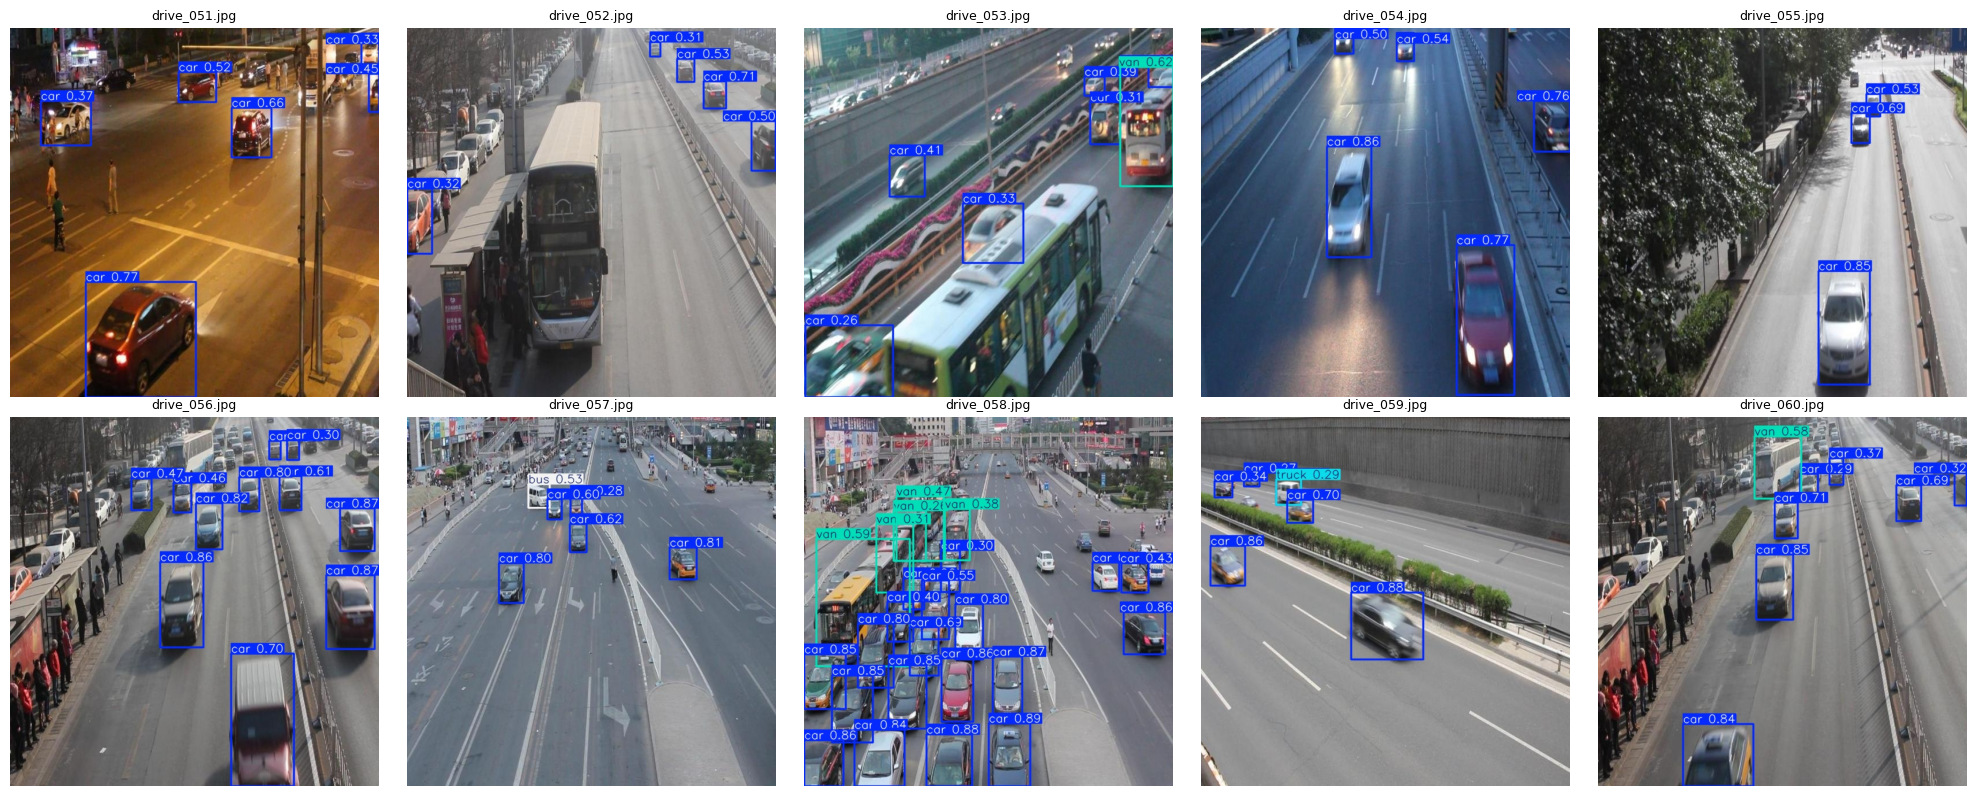

In [7]:
import math
import matplotlib.pyplot as plt
from PIL import Image

pred_images = sorted(PRED_SAVE_DIR.glob('*.jpg'))
cols = 5
rows = math.ceil(len(pred_images) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax, img_path in zip(axes.flat, pred_images):
    ax.imshow(Image.open(img_path))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(pred_images):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Câu hỏi phân tích để nộp

1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.
2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
4. Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?